# 06 — Where does Anthropic's growth stop?

**Question:** Revenue grew 1,127% year over year in Q3-2026. Nobody expects that to continue. But "growth will slow" isn't a forecast: *how fast* it slows and *where it tops out* decide whether the ~$900B compute bill from 03 gets paid. This notebook forecasts revenue, real operating margin and free cash flow to 2030 with a growth curve that **has a ceiling built in**, instead of playing the last quarter's growth forward.

**Short answer**
1. We use a **Gompertz curve**, the standard lopsided S-curve for technology adoption. Growth starts fast and slows *early*, then revenue crawls toward a ceiling. Each quarter, revenue closes a fixed share of the remaining gap to the ceiling, measured in log terms (§1, `06_gompertz_explainer.png`).
2. A curve fitted freely to six quarters puts the ceiling at an absurd ~$1.6 quintillion: the data are too noisy to locate the bend. So we **set the ceiling from outside the data** and let the data pick only the *speed*. With a ceiling of $150–700B, the quarters say half the remaining gap closes every 4–5 quarters, which implies Q4-2026 growth of ~18–37% (§2, `06_growth_vs_size.png`).
3. The **$895B** of commitments is mostly **rent, not capex**: cloud contracts and multi-year leases on chips and data centers, with ~$150–175B more at no fixed price yet. Four take-or-pay deals (Broadcom, Google, Amazon, Microsoft) make up ~$437B of it. Spread out, the bill is about 14 years of today's revenue and nearly 7x the cash pile, and ~$448B of it falls due before 2031 (§3, `06_commitments_by_partner.png`, `06_commitments_in_context.png`).
4. The S-1 gives no revenue guidance. But the compute contracts imply a ceiling of **~$236B a year**, about 3.7x today's run-rate. That's just above the **~$224B breakeven ceiling** (§7), and below ~97% of the worlds we simulate: with Anthropic taking 30–55% of AI spending, our worlds are bigger than what its own contracts are sized for. Valued on its own, the contracts' world is worth ~$18–45 a share (09 §6) (§4).
5. The simulation sizes the ceiling from the S-1's **$40T** of knowledge-work wages: AI's share of that spend × Anthropic's share of AI. It fits each world's speed to the data, then draws 20,000 worlds (§5, `06_simulation_inputs.png`). Median revenue is **~$155B in 2027** and **~$524B in 2030** (P10–P90: $306–907B) (§6, `06_revenue_fan.png`).
6. Median real operating margin: **+5% in 2027, +13% in 2028, +18% in 2030**. Real operating income is positive in **70% / 93% / ~100%** of worlds in those years. No world runs out of cash by 2030. The weak spot is efficiency, not size: worlds that earn less than ~$1.56 of revenue per compute dollar lose cash (owner FCF) on every extra dollar of revenue once they outgrow the contracts (§7, `06_margin_fcf.png`; 08 §3).
7. Compared with 03: 03's base case sits at about our **P3** for 2030 revenue, and its bull case at ~P77. 03's bear case is below every simulated world, so treat it as a stress test, not a central case.

| § | Question | Chart |
|---|---|---|
| 1 | What is a Gompertz curve, and why use one here? | `06_gompertz_explainer.png` |
| 2 | Can we fit one to Anthropic's quarters? | `06_growth_vs_size.png` |
| 3 | What exactly has Anthropic committed to spend? | `06_commitments_by_partner.png`, `06_commitments_in_context.png` |
| 4 | What ceiling are the compute commitments betting on? | — |
| 5 | How does the simulation work, and what goes into it? | `06_simulation_inputs.png` |
| 6 | What revenue does it produce? | `06_revenue_fan.png` |
| 7 | What does that do to margins and free cash flow? | `06_margin_fcf.png` |

**Inputs:** `data/real_earnings.csv` (clean revenue, from 02), `data/quarterly_income_statement.csv`, `data/kpis.csv` (the S-1's market-size figures, named compute deals, SBC backlog), `data/cash_flow.csv`, `data/compute_schedule.csv` (from 03), `data/balance_sheet.csv`.
**Outputs:** `data/forecast.csv` (P10/P25/P50/P75/P90 by year and metric); `data/forecast_worlds.csv` (every world's inputs, Q4-2030 run-rate, revenue and owner FCF by year, for 08's valuation).

**How to read this notebook.** Data are in $ millions, and charts and prose are in $ billions. "P10" means 10% of simulated worlds came in below that number, and P50 is the median. Every assumption lives in the `A` (costs, same values as 03) and `MC` (simulation ranges) dicts in the next cell. Functions are defined once, in the section that first needs them, and reused after that.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

K = load('kpis').drop_duplicates('metric').set_index('metric').value   # S-1 narrative numbers
R = wide(load('real_earnings'), index='metric')                         # revenue, clean revenue (from 02)
Q = wide(load('quarterly_income_statement'))
bs = wide(load('balance_sheet'))
S = load('compute_schedule').set_index('year')                          # committed compute by year (from 03)
B = 1000                                                                # $M -> $B

# --- Costs, as a share of revenue unless noted. Same values as 03's A dict (see 03 for the reasoning) ---
A = dict(cash_opex_pct=0.25, sbc_new_grants_pct=0.04, donations_pct=0.03, capex_pct=0.04, tax_rate=0.21, cash_yield=0.04,
         sbc_ipo_catchup=K['rsu_sbc_catchup_at_ipo'],
         sbc_backlog=K['rsu_unrecognized_sbc'] - K['rsu_sbc_catchup_at_ipo'] + K['option_unrecognized_sbc'])

# --- Simulation ranges (explained in §5) ---
MC = dict(n_worlds=20_000, seed=6,
          ai_share_of_wages=(0.015, 0.08),     # our call: share of the S-1's $40T knowledge-work wages spent on AI (log-uniform)
          anthropic_share_of_ai=(0.30, 0.55),  # our call: Anthropic's slice of that AI spend (uniform); the S-1 gives none
          rev_per_compute=(1.5, 2.5),    # revenue per $1 of compute (uniform); Q3-2026 was 1.72x, Q2-2026 2.08x
          ceiling_growth=K['it_spend_cagr_2006_2025'] / 100)  # the ceiling itself rises ~7%/yr, like IT spend did (S-1)

## 1. What is a Gompertz curve, and why use one here?
**Why ask:** "growth slows down" can mean many shapes. The shape decides how much revenue arrives *before* the ceiling, and that's the part that pays the 2027–2030 compute bill.

**The idea in one sentence:** each quarter, revenue closes a fixed share of the remaining gap to a ceiling, where the gap is measured as a *ratio* (in logs), not in dollars.

$$\underbrace{\ln\frac{R_t}{R_{t-1}}}_{\text{this quarter's growth}} \;=\; c \cdot \underbrace{\ln\frac{K}{R_{t-1}}}_{\text{log gap to the ceiling}}$$

- $R_t$ is revenue (annualized run-rate) in quarter $t$, $K$ is the ceiling, and $c$ is the **speed**, between 0 and 1. With $c = 0.15$, revenue closes 15% of the log gap each quarter, so half the gap is gone in $\ln 2 / 0.15 \approx 4.6$ quarters.
- Equivalently, $R_t = R_{t-1}^{\,1-c} \cdot K^{\,c}$: next quarter's revenue is a weighted (geometric) average of this quarter's revenue and the ceiling.
- **Growth is a straight line in log revenue.** It's fastest when revenue is far below the ceiling and hits zero exactly at it. Plot growth against revenue on a log axis and a Gompertz curve is a straight, falling line. §2 uses exactly that.

**How it compares with the alternatives** (chart below, same starting point, same first-quarter growth, same ceiling):
- **Exponential** (constant growth): no ceiling. It's what "play the last quarter forward" does, and it reaches any number you like.
- **Logistic** (the textbook S-curve): growth falls in proportion to the *dollar* gap, $c\,(1 - R/K)$. It's symmetric: growth holds up until revenue is halfway to the ceiling, then collapses. It fits things with a hard cap that fills evenly, like epidemics or populations with fixed resources.
- **Gompertz:** growth starts falling right away and the last stretch is slow. The inflection point comes at 37% of the ceiling, not 50%. It was first written down in 1825 by the actuary Benjamin Gompertz for mortality. It's the usual fit for tumor growth and for **technology adoption**, such as mobile phones, broadband and enterprise software, where eager adopters arrive quickly and a long tail of reluctant ones takes years.

That lopsided shape fits Anthropic's customer base: developers and AI-native companies came first and fast, while the Fortune 500 and regulated industries are the long tail (per the S-1, >50% of the Fortune 500 are $100K+ customers, but only >30% of the Global 2000). Gompertz is also the more **conservative** choice here. With the same ceiling, it delivers less revenue in 2027–2028, when the compute bill steps up, than a logistic does.

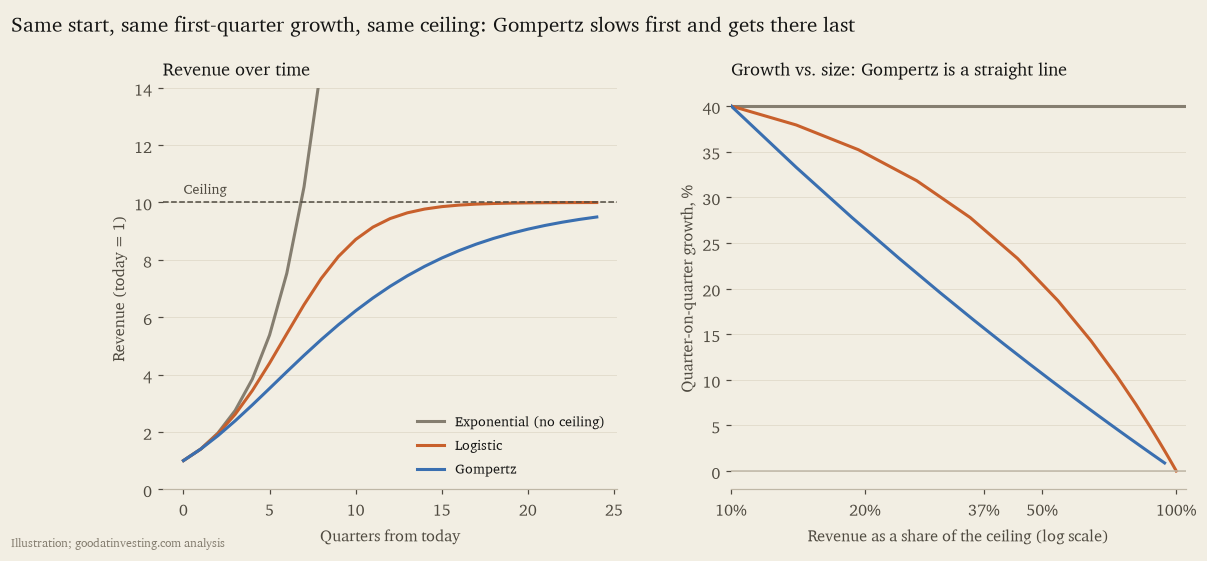

In [2]:
def gompertz_path(start, ceiling, speed, quarters, ceiling_growth=0.0):
    '''Annualized revenue for each future quarter on a Gompertz curve.
    start, ceiling: annualized revenue ($). speed: share of the log gap closed per quarter (0-1).
    ceiling_growth: yearly growth of the ceiling itself. Inputs can be plain numbers or numpy arrays
    (one value per simulated world); the result has one row per quarter.'''
    revenue, path = start, []
    for t in range(1, quarters + 1):
        ceiling_now = ceiling * (1 + ceiling_growth) ** (t / 4)
        revenue = revenue * np.exp(speed * np.log(ceiling_now / revenue))   # close `speed` of the log gap
        path.append(revenue)
    return np.array(path)

def logistic_path(start, ceiling, speed, quarters):
    '''Same idea with the logistic rule: growth = speed x (1 - revenue / ceiling). For the comparison chart only.'''
    revenue, path = start, []
    for _ in range(quarters):
        revenue = revenue * np.exp(speed * (1 - revenue / ceiling))
        path.append(revenue)
    return np.array(path)

# Illustration: start at 1, ceiling 10, and every curve grows 40% in its first quarter
start, ceiling, first_growth, T = 1.0, 10.0, np.log(1.4), 24
c_gz = first_growth / np.log(ceiling / start)        # pick each curve's speed so the first quarter grows 40%
c_lg = first_growth / (1 - start / ceiling)
t = np.arange(T + 1)
curves = {'Exponential (no ceiling)': np.r_[start, start * 1.4 ** t[1:]],
          'Logistic': np.r_[start, logistic_path(start, ceiling, c_lg, T)],
          'Gompertz': np.r_[start, gompertz_path(start, ceiling, c_gz, T)]}
colors = {'Exponential (no ceiling)': NEUTRAL, 'Logistic': SERIES[1], 'Gompertz': SERIES[0]}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for name, y in curves.items():
    ax1.plot(t, y, color=colors[name], label=name)
    ax2.plot(y[:-1] / ceiling, np.expm1(np.diff(np.log(y))) * 100, color=colors[name], label=name)
ax1.axhline(ceiling, color=INK2, ls='--', lw=1)
ax1.text(0, ceiling + 0.3, 'Ceiling', color=INK2, fontsize=9)
ax1.set_ylim(0, 14)
ax1.set_xlabel('Quarters from today')
ax1.set_ylabel('Revenue (today = 1)')
ax1.set_title('Revenue over time', fontsize=11.5, pad=8)
ax1.legend(loc='lower right', fontsize=9)
ax2.set_xscale('log')
ax2.set_xlim(0.1, 1.05)
ax2.set_xticks([0.1, 0.2, 0.37, 0.5, 1], ['10%', '20%', '37%', '50%', '100%'])
ax2.minorticks_off()
ax2.axhline(0, color=AXIS, lw=1)
ax2.set_xlabel('Revenue as a share of the ceiling (log scale)')
ax2.set_ylabel('Quarter-on-quarter growth, %')
ax2.set_title('Growth vs. size: Gompertz is a straight line', fontsize=11.5, pad=8)
fig.suptitle('Same start, same first-quarter growth, same ceiling: Gompertz slows first and gets there last',
             x=0.01, ha='left', fontsize=14)
fig.subplots_adjust(top=0.84, wspace=0.25)
source(fig, 'Illustration; goodatinvesting.com analysis')
save(fig, '06_gompertz_explainer.png')
plt.show()

**What this shows** (`06_gompertz_explainer.png`): on the left, all three curves start together. Exponential runs off the chart in a few years. Logistic keeps nearly full speed until about half the ceiling, then stops abruptly. Gompertz bends from the first quarter and takes longest to reach the top. On the right, Gompertz growth falls along a straight line when revenue is on a log axis, and hits zero at the ceiling. The logistic line stays flat and then drops off a cliff.

Two practical points for what follows:
1. A Gompertz curve has just **two dials**: the ceiling $K$ and the speed $c$. Give it today's revenue and those two numbers, and the whole future path is fixed.
2. Because growth is a straight line against log revenue, we can **estimate the line from history**: plot each quarter's growth against the revenue it started from, and fit.

**Next:** does Anthropic's history give us those two dials?

## 2. Can we fit one to Anthropic's quarters?
**Why ask:** we'd rather let the data choose the curve than pick one by hand.

**Method, attempt 1: fit both dials freely.** Regress each quarter's log growth $g_t$ on the log of the revenue it started from:
$g_t = a - c \ln R_{t-1}$. The slope gives the speed $c$. The ceiling is where the line hits zero growth, $K = e^{a/c}$. Revenue is annualized (quarter × 4), and 2026 quarters are net of the 6% policy-violator revenue, as in 02.

In [3]:
quarters_hist = ['Q1-2025', 'Q2-2025', 'Q3-2025', 'Q4-2025', 'Q1-2026', 'Q2-2026', 'Q3-2026']
quarterly = R.loc['revenue', quarters_hist].copy()
quarterly[quarters_hist[4:]] = R.loc['clean_revenue', quarters_hist[4:]]   # 2026: net of policy violators (02 §3)
run_rate = quarterly * 4                       # annualized revenue, $M
growth = np.log(run_rate).diff().dropna()      # log growth each quarter (0.38 = +47%)
start_level = run_rate.shift(1).dropna()       # the run-rate each quarter's growth started from
run_now = run_rate['Q3-2026']                  # where the forecast starts: ~$64B a year

slope, intercept = np.polyfit(np.log(start_level), growth, 1)
print(f'Free fit: speed c = {-slope:.3f}, ceiling = e^(a/c) = ${np.exp(-intercept / slope) / B:,.0f}B a year')
pd.DataFrame({'run-rate at start, $B': start_level / B, 'q/q growth %': np.expm1(growth) * 100}).round(1)

Free fit: speed c = 0.033, ceiling = e^(a/c) = $1,561,468,247B a year


,"run-rate at start, $B",q/q growth %
period,,
Q2-2025,1.5,109.3
Q3-2025,3.1,75.6
Q4-2025,5.5,47.6
Q1-2026,8.2,118.0
Q2-2026,17.8,144.2
Q3-2026,43.4,46.7


**That's useless:** a ceiling of ~$1.6 quintillion, roughly 10,000 times world GDP. The reason is in the formula. The ceiling is $e^{a/c}$, the *exponential* of the intercept divided by the slope. Growth zig-zagged (fast in H1-2025, slower in late 2025, re-accelerating in H1-2026 with Claude Code, then back to +47% in Q3), so the fitted slope is nearly flat ($c \approx 0.03$). Dividing by a number close to zero and then exponentiating turns a small wobble in the slope into many orders of magnitude in the ceiling. Six noisy points from the steep part of the curve can't show where it bends.

**Method, attempt 2: give it the ceiling, fit only the speed.** If we fix $K$ from outside (market size, §5), the model has one unknown left. Each quarter gives one equation, $g_t = c \cdot \ln(K / R_{t-1})$, and the best $c$ in the least-squares sense is

$$\hat c = \frac{\sum_t g_t \, L_t}{\sum_t L_t^2}, \qquad L_t = \ln\frac{K}{R_{t-1}}, \qquad \text{standard error } \;\text{se}(\hat c) = \sqrt{\frac{\sum_t (g_t - \hat c L_t)^2}{(n-1)\sum_t L_t^2}}$$

This is ordinary regression through the origin. It's stable because we're estimating a slope, not dividing by one. The standard error tells us how unsure the data leave us about the speed, and the simulation uses it in §5.

In [4]:
def fit_speed(ceiling):
    '''Best-fitting Gompertz speed for a given ceiling (annual $M; a number or an array of them).
    Returns (speed, standard error), using the history in `growth` and `start_level`.'''
    ceiling = np.atleast_1d(ceiling).astype(float)
    gap = np.log(ceiling[:, None] / start_level.values[None, :])        # L_t: one row per ceiling, one column per quarter
    speed = (gap * growth.values).sum(axis=1) / (gap ** 2).sum(axis=1)
    resid = growth.values - speed[:, None] * gap
    se = np.sqrt((resid ** 2).sum(axis=1) / (len(growth) - 1) / (gap ** 2).sum(axis=1))
    return speed, se

def next_quarter_growth(ceiling, speed):
    '''The q/q growth a curve implies for Q4-2026, starting from today's run-rate.'''
    return np.expm1(speed * np.log(ceiling * (1 + MC['ceiling_growth']) ** 0.25 / run_now))

examples = np.array([150e3, 300e3, 700e3])           # illustrative ceilings, $M a year
ex_speed, ex_se = fit_speed(examples)
pd.DataFrame({'ceiling, $B/yr': examples / B, 'speed c': ex_speed, '± se': ex_se,
              'quarters to close half the gap': np.log(2) / ex_speed,
              'implied Q4-2026 growth %': next_quarter_growth(examples, ex_speed) * 100}).round(3)

,"ceiling, $B/yr",speed c,± se,quarters to close half the gap,implied Q4-2026 growth %
0,150.0,0.187,0.037,3.708,17.716
1,300.0,0.158,0.028,4.397,27.997
2,700.0,0.131,0.021,5.271,37.341


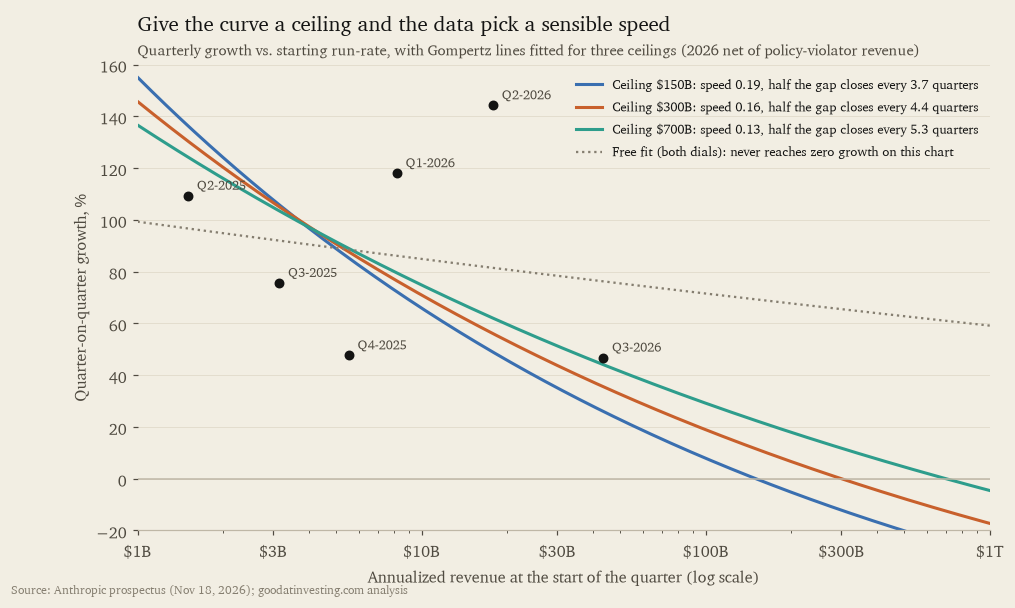

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))
xs = np.geomspace(1e3, 1e6, 300)
for k, c, col in zip(examples, ex_speed, SERIES):
    ax.plot(xs / B, np.expm1(c * np.log(k / xs)) * 100, color=col,
            label=f'Ceiling ${k/B:,.0f}B: speed {c:.2f}, half the gap closes every {np.log(2)/c:.1f} quarters')
ax.plot(xs / B, np.expm1(intercept + slope * np.log(xs)) * 100, color=NEUTRAL, ls=':', lw=1.5,
        label='Free fit (both dials): never reaches zero growth on this chart')
ax.scatter(start_level / B, np.expm1(growth) * 100, color=INK, zorder=3, s=30)
for q, x, y in zip(growth.index, start_level / B, np.expm1(growth) * 100):
    ax.annotate(q, (x, y), xytext=(6, 4), textcoords='offset points', fontsize=8.5, color=INK2)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xscale('log')
ax.set_xticks([1, 3, 10, 30, 100, 300, 1000], ['$1B', '$3B', '$10B', '$30B', '$100B', '$300B', '$1T'])
ax.set_xlim(1, 1000)
ax.set_ylim(-20, 160)
ax.set_xlabel('Annualized revenue at the start of the quarter (log scale)')
ax.set_ylabel('Quarter-on-quarter growth, %')
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title('Give the curve a ceiling and the data pick a sensible speed')
subtitle(ax, 'Quarterly growth vs. starting run-rate, with Gompertz lines fitted for three ceilings (2026 net of policy-violator revenue)')
source(fig)
save(fig, '06_growth_vs_size.png')
plt.show()

**What this shows** (`06_growth_vs_size.png`): the dots are the six quarters. Each solid line is the Gompertz curve fitted for a given ceiling, and it reaches zero growth exactly at that ceiling. All three fit the history about equally well, because they differ mainly beyond the data. They agree on a speed of **~0.13–0.19 a quarter**: half the remaining gap to the ceiling closes every 4–5 quarters. The ceilings do differ on what comes next: Q4-2026 growth of ~18% if the ceiling is $150B, and ~37% if it's $700B. Q3 was +47% (clean).

This is how we keep the curve reasonable: **the ceiling comes from the market, the speed comes from the data.** A higher ceiling automatically means faster growth today, so the two aren't chosen independently.

**Next:** before sizing the market ourselves, look at the bet Anthropic has already placed: its compute contracts. What's in them?

## 3. What exactly has Anthropic committed to spend?
**Why ask:** "$895 billion of commitments" gets quoted a lot, often as "capex." Most of it isn't capex, and not all of it is equally binding. Before we use the commitments to infer a revenue ceiling (§4), here's what the number contains, in plain terms.

**Three words first.**
- **Capex** (capital expenditure) means buying something you own, like a server, and writing it off over its useful life. Anthropic's actual capex is small. Owned equipment, equipment prepayments and finance-lease principal together came to about **$3B** in 9M-2026.
- **Purchase commitment:** a promise to buy at least a set amount of someone else's compute (Google's, Amazon's or Microsoft's cloud). It's booked as an operating cost as it's used. The big ones are **take-or-pay**: if Anthropic uses less, it pays the shortfall anyway (the S-1 calls this a "true-up").
- **Lease:** renting chips or data-center space for years. Economically, a lease is capex paid in installments: you get the asset now and owe rent for 5–20 years. The Broadcom TPU leases are booked this way, as *finance leases*.

So "committed spend" looks more like a giant rent-and-subscription bill than a construction program. That matters because a construction program can be paused, and rent can't.

**Method:** two cuts of the same commitments, all from the S-1's MD&A (Contractual Obligations and Infrastructure Service Arrangements).
1. **By partner:** the deals the S-1 names, grouped by how hard each is to walk away from. The part of the $895.4B the named deals don't cover is shown as "not itemized."
2. **By scale:** set next to things a reader can picture: cash on hand, today's revenue, today's compute bill.

For the year-by-year payment schedule, see 03 §1 (`03_compute_commitments.png`).

In [6]:
KP = load('kpis').drop_duplicates('metric').set_index('metric')     # value plus the S-1's qualifier ('>', '<', '~')

# The deals the S-1 names, and how hard each one is to walk away from (MD&A, "Infrastructure Service Arrangements").
DEALS = [  # (label, kpis metric, how binding)
    ('Broadcom: TPU leases',  'commit_broadcom_leases',     'Must pay'),            # finance leases, non-cancelable
    ('Google: cloud',         'commit_google_csp',          'Must pay'),            # take-or-pay with true-up
    ('Amazon: cloud',         'commit_amazon',              'Must pay'),            # take-or-pay with true-up
    ('Microsoft: cloud',      'commit_microsoft',           'Must pay'),            # "regardless of actual usage"
    ('Lambda: GPUs',          'commit_lambda',              'Pay once delivered'),  # $34.9B of it ends if Lambda can't lease the site
    ('Nscale: GPUs',          'commit_nscale',              'Pay once delivered'),  # Nscale must first find financing
    ('SpaceXAI: GPUs',        'commit_spacexai',            'Cancellable'),         # 90 days' notice after early 2027
    ('Google: extra TPUs',    'commit_google_tpu_variable', 'No fixed price'),      # $125-150B estimate, delivered 2028-31
    ('AMD: Helios racks',     'commit_amd_variable',        'No fixed price'),      # "exceed $20.0 billion"
]
deals = pd.DataFrame(DEALS, columns=['deal', 'metric', 'binding'])
deals['usd'] = KP.loc[deals.metric, 'value'].values
deals['approx'] = KP.loc[deals.metric, 'approx'].fillna('').values

# Whatever part of the $895.4B the named fixed-price deals don't explain. Assumes they all sit inside it (the S-1 doesn't say).
not_itemized = K['commitments_all_in'] - deals.loc[deals.binding != 'No fixed price', 'usd'].sum()
assert not_itemized > 0
deals.loc[len(deals)] = ['Not itemized by partner', '', 'Not itemized', not_itemized, '~']

must_pay = deals.loc[deals.binding == 'Must pay', 'usd'].sum()
google = deals.loc[deals.deal.str.startswith('Google'), 'usd'].sum()
print(f'Must-pay deals: ${must_pay/B:,.0f}B = {must_pay/K["commitments_all_in"]:.0%} of the $895.4B')
print(f'Google, cloud + extra TPUs: ${google/B:,.0f}B (Broadcom\'s leased chips are TPUs too)')
deals.assign(usd_b=(deals.usd / B).round(1)).drop(columns=['metric', 'usd'])

Must-pay deals: $437B = 49% of the $895.4B
Google, cloud + extra TPUs: $259B (Broadcom's leased chips are TPUs too)


,deal,binding,approx,usd_b
0,Broadcom: TPU leases,Must pay,~,161.2
1,Google: cloud,Must pay,>,121.3
2,Amazon: cloud,Must pay,>,110.0
3,Microsoft: cloud,Must pay,>,44.9
4,Lambda: GPUs,Pay once delivered,~,41.3
5,Nscale: GPUs,Pay once delivered,<,44.6
6,SpaceXAI: GPUs,Cancellable,<,120.5
7,Google: extra TPUs,No fixed price,~,137.5
8,AMD: Helios racks,No fixed price,>,20.0
9,Not itemized by partner,Not itemized,~,251.6


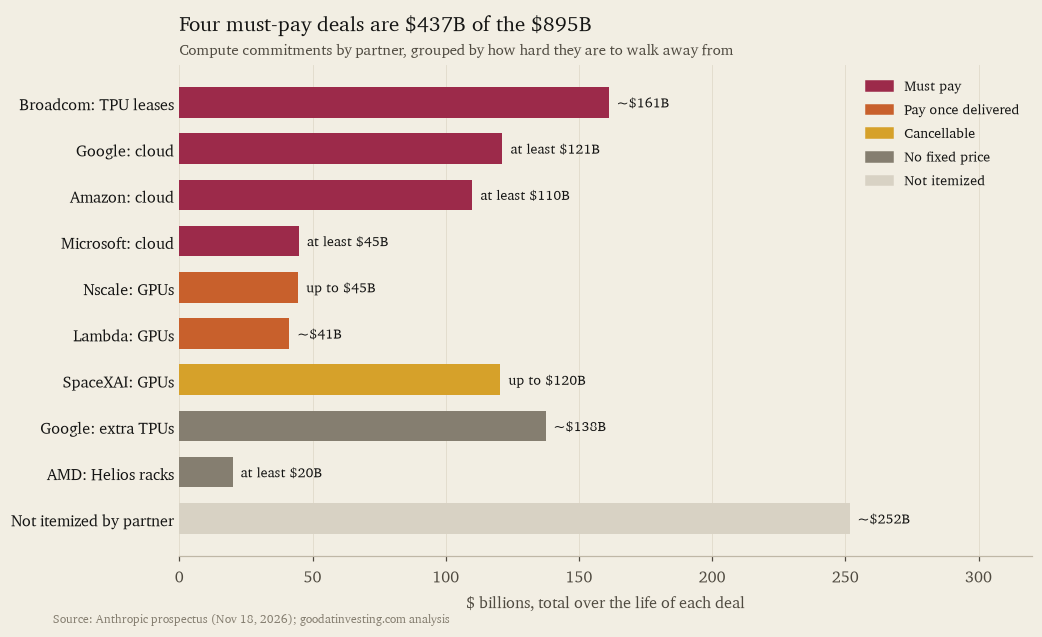

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.8))
BIND_COLOR = {'Must pay': NEG, 'Pay once delivered': SERIES[1], 'Cancellable': SERIES[3],
              'No fixed price': NEUTRAL, 'Not itemized': PALE}
QUAL = {'>': 'at least ', '<': 'up to ', '~': '~'}                # how the S-1 words each amount
order = deals.assign(g=deals.binding.map(list(BIND_COLOR).index)).sort_values(['g', 'usd'], ascending=[False, True])
y = np.arange(len(order))
ax.barh(y, order.usd / B, color=order.binding.map(BIND_COLOR), height=0.66)
for yi, (v, q) in enumerate(zip(order.usd / B, order.approx)):
    ax.text(v + 3, yi, f'{QUAL.get(q, "")}${v:,.0f}B', va='center', fontsize=9, color=INK)
ax.set_yticks(y, order.deal)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlim(0, 320)
ax.set_xlabel('$ billions, total over the life of each deal')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=b) for b, col in BIND_COLOR.items()], loc='upper right', fontsize=9)
ax.set_title(f'Four must-pay deals are ${must_pay/B:,.0f}B of the ${K["commitments_all_in"]/B:,.0f}B')
subtitle(ax, 'Compute commitments by partner, grouped by how hard they are to walk away from')
source(fig)
save(fig, '06_commitments_by_partner.png')
plt.show()

**What this shows** (`06_commitments_by_partner.png`):
- **Must pay (red):** Broadcom's TPU leases and the Google, Amazon and Microsoft cloud contracts are non-cancelable unless the partner breaches. Google and Amazon charge a true-up if usage falls short. These four alone are about half the $895B.
- **Pay once delivered (orange):** Lambda and Nscale bill only when capacity is delivered and accepted. Both depend on the partner getting a site or financing first. Most of the S-1's **$213.8B** "subject to termination rights or contingent conditions" probably sits in this group and in the not-itemized remainder.
- **Cancellable (yellow):** SpaceXAI, up to $120.5B into 2029 at ~$3.1B a month. Either side can cancel on 90 days' notice after early 2027. It's the escape valve if demand disappoints.
- **No fixed price (gray):** Google's extra TPUs (~$125–150B, delivered 2028–31) and AMD's Helios racks (>$20B). These are *on top of* the $895B.
- **Concentration:** Google is on both sides of the table. Google-related deals (cloud plus extra TPUs) total ~$259B, and Broadcom's leased chips are Google-designed TPUs. Google is also an Anthropic shareholder.
- **Not itemized (light gray):** the ~$250B residual. The S-1 says the post-September commitments are "primarily … data center leases," and most of the $451B of leases that haven't started yet are data-center space, so this bar is mostly buildings and power. This is our reading, not a disclosed split.

The S-1 also lets several partners take part of their payment in Anthropic paper: up to **$77B** of convertible notes under the partner note-purchase agreements (04 covers the dilution). So not every committed dollar has to be paid in cash.

**Next:** how big is the total next to numbers we can picture?

In [8]:
cash = bs.loc[['Cash and cash equivalents', 'Short-term investments'], '2026-09-30'].sum()
compute_now = Q.loc['Compute and infrastructure', 'Q3-2026'] * 4                  # today's compute bill, annualized
cf = load('cash_flow').query("period == '9M-2026'").set_index('line_item').value
capex_9m = -cf[['Purchases of property and equipment', 'Prepayments for leased assets and equipment',
                'Principal payments for finance leases']].sum()                    # what Anthropic actually spent on owned/leased kit
variable = (K['commitments_variable_low'] + K['commitments_variable_high']) / 2   # midpoint of the S-1's $150-175B
firm = K['commitments_all_in'] - K['commitments_contingent_or_terminable']

# Committed payments per year (03's schedule, including the variable deals), in units a reader can picture
commit = pd.Series({'Q4-2026': S.loc[2026].sum(), **{str(y): S.loc[y].sum() for y in range(2027, 2031)}})
per_year = commit.drop('Q4-2026')
print(f'Total = {K["commitments_all_in"]/run_now:.1f} years of today\'s (clean) revenue run-rate, '
      f'{K["commitments_all_in"]/cash:.1f}x cash + short-term investments, ~{K["commitments_all_in"]/capex_9m:,.0f}x 9M-2026 capex-like spend')
pd.DataFrame({'committed $B': per_year / B,
              '$M per day': per_year / 365,
              "x today's compute bill": per_year / compute_now,
              "x today's revenue run-rate": per_year / run_now}).round(1)

Total = 14.0 years of today's (clean) revenue run-rate, 6.8x cash + short-term investments, ~302x 9M-2026 capex-like spend


,committed $B,$M per day,x today's compute bill,x today's revenue run-rate
2027,83.0,227.4,2.1,1.3
2028,107.6,294.8,2.7,1.7
2029,131.7,360.9,3.3,2.1
2030,128.2,351.2,3.2,2.0


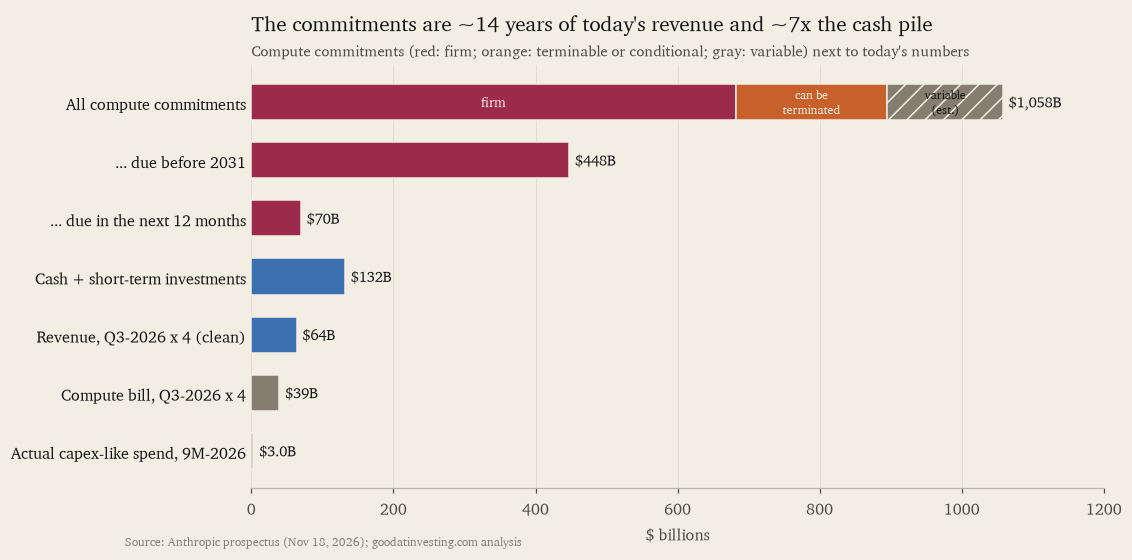

In [9]:
rows = [  # (label, [(value, color, hatch), ...])
    ('All compute commitments',              [(firm, NEG, ''), (K['commitments_contingent_or_terminable'], SERIES[1], ''),
                                              (variable, NEUTRAL, '//')]),
    ('  ... due before 2031',                [(K['commitments_before_2031'], NEG, '')]),
    ('  ... due in the next 12 months',      [(K['commitments_due_next_12m'], NEG, '')]),
    ('Cash + short-term investments',        [(cash, POS, '')]),
    ("Revenue, Q3-2026 x 4 (clean)",         [(run_now, POS, '')]),
    ('Compute bill, Q3-2026 x 4',            [(compute_now, NEUTRAL, '')]),
    ('Actual capex-like spend, 9M-2026',     [(capex_9m, NEUTRAL, '')]),
]
fig, ax = plt.subplots(figsize=(10, 5))
for i, (label, parts) in enumerate(rows):
    left = 0
    for v, col, h in parts:
        ax.barh(i, v / B, left=left, color=col, hatch=h, edgecolor=SURFACE, height=0.62)
        left += v / B
    ax.text(left + 8, i, f'${left:,.0f}B' if left >= 10 else f'${left:,.1f}B', va='center', fontsize=9.5, color=INK)
ax.text(firm / 2 / B, 0, 'firm', ha='center', va='center', color=SURFACE, fontsize=9)
ax.text((firm + K['commitments_contingent_or_terminable'] / 2) / B, 0, 'can be\nterminated', ha='center', va='center',
        color=SURFACE, fontsize=8)
ax.text((K['commitments_all_in'] + variable / 2) / B, 0, 'variable\n(est.)', ha='center', va='center', color=INK, fontsize=8)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlim(0, 1200)
ax.set_xlabel('$ billions')
ax.set_title(f"The commitments are ~{K['commitments_all_in']/run_now:.0f} years of today's revenue "
             f"and ~{K['commitments_all_in']/cash:.0f}x the cash pile")
subtitle(ax, "Compute commitments (red: firm; orange: terminable or conditional; gray: variable) next to today's numbers")
source(fig)
save(fig, '06_commitments_in_context.png')
plt.show()

**What this shows** (`06_commitments_in_context.png`):
- **The total is long-dated.** $895B sounds like a bill that's due now. About half of it (~$448B) falls due before 2031, ~$70B in the next 12 months, and the rest runs to 2045. The useful comparison is the yearly payment, in the table above: committed compute goes from ~$83B in 2027 to ~$130B a year in 2029–30, which is **2.1–3.3x today's compute bill** and **1.3–2.1x today's revenue run-rate**, every year.
- **It's not capex.** Anthropic's capex-like spending was ~$3B in nine months. The $895B is almost all rent and cloud contracts, which arrive as operating costs (compute and infrastructure) and lease payments. That's why §7 treats it as a near-fixed cost, with capex as a small separate line.
- **Cash covers the next 12 months, not the next five years.** $132B of cash and short-term investments covers ~$70B of payments due in the next year. It doesn't cover $448B due by 2030. The gap gets closed by revenue (the bet in §4), new capital, or the termination and cancellation rights in the orange segment.
- **About a quarter is soft.** $214B can be terminated or depends on a partner meeting conditions, and SpaceXAI can be cancelled. In a downturn, these are the first things Anthropic would cut.

**Next:** a company doesn't sign for $130B a year of compute without a revenue plan. What plan do these contracts imply?

## 4. What ceiling are the compute commitments betting on?
**Why ask:** the S-1 gives no revenue guidance. The only forward statement is "we expect our revenue growth rate to decline over time," and Run-Rate Revenue is blank in this amendment. But nobody signs ~$130B a year of compute without a revenue plan. 03 §2 turned the commitments into revenue at today's efficiency: committed compute × 1.72 (Q3-2026 revenue per compute dollar) ≈ **$226B in 2029**.

**Method:** run the curve backwards. For each candidate ceiling, fit the speed (§2), project to 2029, and find the ceiling whose 2029 revenue equals the commitment-implied $226B. Annual revenue is the average of the four quarterly run-rates in each year.

In [10]:
YEARS = ['Q4-2026', '2027', '2028', '2029', '2030']
future_q = [f'Q{(i + 2) % 4 + 1}-{2026 + (i + 2) // 4}' for i in range(1, 18)]   # Q4-2026 ... Q4-2030
year_of = ['Q4-2026' if q == 'Q4-2026' else q[-4:] for q in future_q]

def to_years(path):
    '''Quarterly run-rates (quarters x worlds) -> revenue per year (worlds x years). A year's revenue = mean run-rate.
    Q4-2026 is a single quarter, so it's run-rate / 4.'''
    df = pd.DataFrame(path, index=future_q) / 4
    return df.groupby(year_of).sum().T[YEARS]

rpc_q3 = Q.loc['Revenue', 'Q3-2026'] / Q.loc['Compute and infrastructure', 'Q3-2026']
implied = commit * rpc_q3                                         # 03 §2: revenue the commitments are sized for

grid = np.geomspace(run_now * 1.2, 3e6, 400)                       # candidate ceilings, $M a year
rev_2029 = to_years(gompertz_path(run_now, grid, fit_speed(grid)[0], len(future_q), MC['ceiling_growth']))['2029']
k_commit = np.interp(implied['2029'], rev_2029.values, grid)       # 2029 revenue rises with the ceiling, so interpolate
c_commit = fit_speed(k_commit)[0]
path_commit = to_years(gompertz_path(run_now, k_commit, c_commit, len(future_q), MC['ceiling_growth'])).iloc[0]
print(f'Ceiling the commitments imply: ${k_commit/B:,.0f}B a year today = {k_commit/run_now:.1f}x the Q3 run-rate '
      f'= {k_commit/K["knowledge_work_value"]:.2%} of the $40T of knowledge-work wages')
pd.DataFrame({'commitment-implied revenue': implied, 'Gompertz path at that ceiling': path_commit}).T.div(B).round(0)

Ceiling the commitments imply: $236B a year today = 3.7x the Q3 run-rate = 0.59% of the $40T of knowledge-work wages


,Q4-2026,2027,2028,2029,2030
commitment-implied revenue,19.0,143.0,185.0,226.0,220.0
Gompertz path at that ceiling,20.0,120.0,180.0,226.0,262.0


**What this shows:** the contracts make sense if Anthropic's revenue ceiling today is about **$236B a year**, roughly 3.7x the clean Q3 run-rate of ~$64B and about half of 1% of the $40T the S-1 cites. That's the company's **revealed forecast**: aggressive, but not a bet on taking over the economy. The fitted path and the commitment line aren't the same shape: the curve front-loads growth, while the contracts step up in 2028–2029 as new data centers come online. That mismatch is the margin squeeze the S-1 warns about.

One catch: this uses Q3's 1.72x revenue per compute dollar. If efficiency improves (Q2 hit 2.08x), the same contracts serve more revenue and imply a higher ceiling.

Compare this with the breakeven ceiling in §7, and with §5's range: with Anthropic taking 30–55% of AI spending, our lowest ceiling is ~$180B, and the contracts sit at about the 3rd percentile of our worlds. Either the company is under-ordering compute for the market it expects to win (it can always buy more), or our share range is generous. 09 §6 values the contracts' world on its own: ~$18 a share at Q3's efficiency, ~$45 at Q2's.

**Next:** is that ceiling a lot or a little? Size it from the market, and allow for being wrong.

## 5. How does the simulation work, and what goes into it?
**Why simulate:** we don't know the ceiling, the speed or the cost efficiency, and the answer depends on all three together. Instead of three hand-picked scenarios (as in 03), we draw **20,000 possible worlds**. Each one gets its own combination of inputs, runs through the same model, and lands on one outcome. The spread of those outcomes is the forecast. This is a **Monte Carlo simulation**: random draws stand in for honest uncertainty, and each range below reflects what we think is plausible.

**The inputs, one row per world:**

| Input | Range | How it's drawn | Why this range |
|---|---|---|---|
| AI's share of knowledge-work wages $w$ (`ai_share_of_wages`) | 1.5%–8% | log-uniform | For scale, cloud spend ($1.9T, S-1) is 4.75% of the $40T after 20 years. Log-uniform gives each doubling (2%→4%→8%) equal odds, the honest choice when we're unsure even of the order of magnitude. |
| Anthropic's share $m$ of that AI spend (`anthropic_share_of_ai`) | 30%–55% | uniform | Our call: Anthropic stays the leading vendor of AI for knowledge work, from first among several frontier labs and hyperscalers to about half the market. The S-1 gives no market share. |
| **Ceiling** $K = \$40\text{T} \times w \times m$ | ~$180B–$1.8T a year | calculated | Then grows 7% a year, like IT spend (S-1). |
| **Speed** $c$ | fitted, ± its error | normal around §2's fit for *that world's* ceiling | Ties speed to the data and to the ceiling: high-ceiling worlds grow faster now. |
| Revenue per $1 of compute | 1.5x–2.5x | uniform | Q3-2026 1.72x, Q2-2026 2.08x. Covers price cuts eating efficiency gains, and the reverse. |

Everything else (cash opex, stock comp, donations, capex, tax, the compute commitment schedule) is fixed at 03's values, so the spread here comes only from these inputs. The `seed` makes the draws repeatable.

In [11]:
def draw_worlds(n, seed):
    '''One row per simulated world, holding every random input the model needs.'''
    rng = np.random.default_rng(seed)
    w = pd.DataFrame({
        'ai_share_of_wages': np.exp(rng.uniform(*np.log(MC['ai_share_of_wages']), n)),   # log-uniform: uniform in log space
        'anthropic_share_of_ai': rng.uniform(*MC['anthropic_share_of_ai'], n),
        'rev_per_compute': rng.uniform(*MC['rev_per_compute'], n),
    })
    w['ceiling'] = K['knowledge_work_value'] * w.ai_share_of_wages * w.anthropic_share_of_ai       # $M a year, today
    speed, se = fit_speed(w.ceiling.values)                                         # §2's fit for each world's ceiling
    w['speed'] = rng.normal(speed, se).clip(0.02, 0.9)       # data uncertainty; the clip only trims rare extreme draws
    w['next_q_growth'] = next_quarter_growth(w.ceiling, w.speed)
    return w

worlds = draw_worlds(MC['n_worlds'], MC['seed'])
assert (worlds.ceiling > run_now).all(), 'every ceiling should sit above today’s run-rate'
print(f"Speed clipped in {((worlds.speed == 0.02) | (worlds.speed == 0.9)).mean():.1%} of worlds")
worlds.describe(percentiles=[0.1, 0.5, 0.9]).loc[['10%', '50%', '90%']].assign(ceiling=lambda d: d.ceiling / B).round(3)

Speed clipped in 0.0% of worlds


,ai_share_of_wages,anthropic_share_of_ai,rev_per_compute,ceiling,speed,next_q_growth
10%,0.018,0.325,1.600,293.213,0.105,0.245
50%,0.034,0.425,2.006,571.343,0.136,0.348
90%,0.067,0.525,2.402,1157.565,0.174,0.463


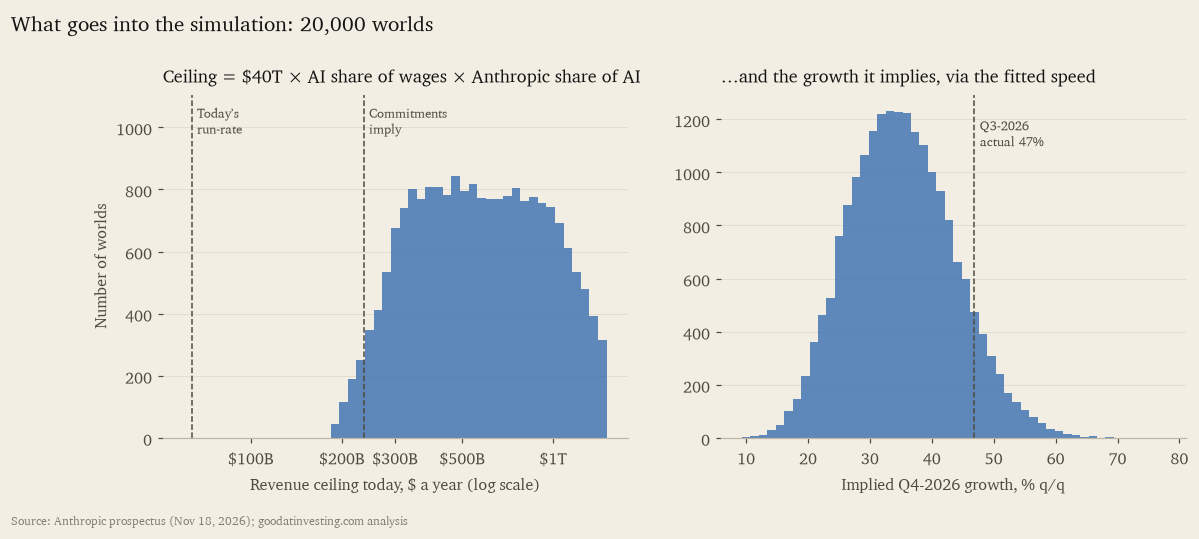

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.hist(worlds.ceiling / B, bins=np.geomspace(60, 1500, 50), color=SERIES[0], alpha=0.8)
ax1.set_xscale('log')
ax1.set_xticks([100, 200, 300, 500, 1000], ['$100B', '$200B', '$300B', '$500B', '$1T'])
ax1.minorticks_off()
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.25)   # headroom for the labels
for x, txt in ((run_now / B, 'Today’s\nrun-rate'), (k_commit / B, 'Commitments\nimply')):
    ax1.axvline(x, color=INK2, ls='--', lw=1)
    ax1.text(x * 1.04, ax1.get_ylim()[1] * 0.97, txt, color=INK2, fontsize=8.5, va='top')
ax1.set_xlabel('Revenue ceiling today, $ a year (log scale)')
ax1.set_ylabel('Number of worlds')
ax1.set_title('Ceiling = $40T × AI share of wages × Anthropic share of AI', fontsize=11.5, pad=8)
ax2.hist(worlds.next_q_growth * 100, bins=50, color=SERIES[0], alpha=0.8)
q3 = np.expm1(growth['Q3-2026']) * 100
ax2.axvline(q3, color=INK2, ls='--', lw=1)
ax2.text(q3 + 1, ax2.get_ylim()[1] * 0.85, f'Q3-2026\nactual {q3:.0f}%', color=INK2, fontsize=8.5)
ax2.set_xlabel('Implied Q4-2026 growth, % q/q')
ax2.set_title('…and the growth it implies, via the fitted speed', fontsize=11.5, pad=8)
fig.suptitle(f'What goes into the simulation: {len(worlds):,} worlds', x=0.01, ha='left', fontsize=14)
fig.subplots_adjust(top=0.82, bottom=0.17, wspace=0.2)
source(fig)
save(fig, '06_simulation_inputs.png')
plt.show()

**What this shows** (`06_simulation_inputs.png`): on the left, the ceiling runs from about $180B to $1.8T a year, with a median of ~$570B. The commitment-implied ceiling from §4 (~$236B) sits below ~97% of worlds. On the right, the near-term growth those ceilings imply, through the fitted speed, is mostly **25–46% (P10–P90)** q/q for Q4-2026. The median (~35%) is below Q3's +47%, consistent with the S-1's warning that growth will decline, and with ~$600M of price cuts already showing up in Q3.

**Next:** run every world forward.

## 6. What revenue does it produce?
**Method:** for each world, start at the Q3-2026 run-rate and apply the Gompertz rule (§1) quarter by quarter with that world's ceiling and speed, through Q4-2030. The arrays below hold one column per world, so the loop in `gompertz_path` runs once for all 20,000. Then we summarize each year by percentiles.

In [13]:
PCTS = [0.10, 0.25, 0.50, 0.75, 0.90]

def percentiles(df):
    '''worlds x years -> P10/P25/P50/P75/P90 x years'''
    return df.quantile(PCTS).rename(index=lambda q: f'P{q * 100:.0f}')

path = gompertz_path(run_now, worlds.ceiling.values, worlds.speed.values, len(future_q), MC['ceiling_growth'])
revenue = to_years(path)                                           # worlds x years, $M
fy2026 = R.loc['revenue', '9M-2026'] + revenue['Q4-2026']           # 9 months reported + simulated Q4
rev_pct = percentiles(pd.concat([fy2026.rename('FY2026'), revenue[YEARS[1:]]], axis=1))

p03 = load('projections').query('metric == "revenue"').pivot(index='scenario', columns='period', values='value')
for s in p03.index:
    print(f"03 {s}: 2027 ${p03.loc[s, '2027']/B:,.0f}B = our P{(revenue['2027'] < p03.loc[s, '2027']).mean()*100:.0f}; "
          f"2030 ${p03.loc[s, '2030']/B:,.0f}B = our P{(revenue['2030'] < p03.loc[s, '2030']).mean()*100:.0f}")
print('Median growth by year:', (rev_pct.loc['P50'].pct_change() * 100).round(0).dropna().to_dict())
(rev_pct / B).round(0)

03 Base: 2027 $120B = our P7; 2030 $261B = our P3
03 Bear: 2027 $81B = our P0; 2030 $106B = our P0
03 Bull: 2027 $177B = our P74; 2030 $746B = our P77
Median growth by year: {'2027': 184.0, '2028': 83.0, '2029': 45.0, '2030': 27.0}


,FY2026,2027,2028,2029,2030
P10,53.0,123.0,194.0,256.0,306.0
P25,54.0,137.0,230.0,314.0,383.0
P50,55.0,155.0,284.0,412.0,524.0
P75,56.0,178.0,354.0,545.0,724.0
P90,57.0,198.0,420.0,669.0,907.0


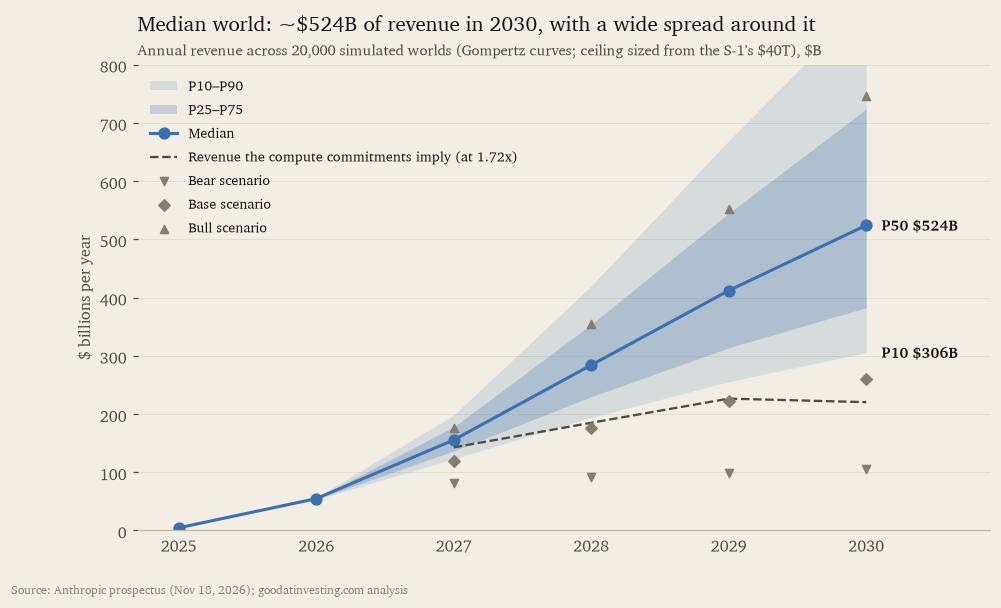

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
lab = ['2025', '2026', '2027', '2028', '2029', '2030']
x = np.arange(len(lab))
band = lambda p: np.r_[R.loc['revenue', 'FY2025'], rev_pct.loc[p]] / B
ax.fill_between(x, band('P10'), band('P90'), color=SERIES[0], alpha=0.15, lw=0, label='P10–P90')
ax.fill_between(x, band('P25'), band('P75'), color=SERIES[0], alpha=0.25, lw=0, label='P25–P75')
ax.plot(x, band('P50'), color=SERIES[0], marker='o', label='Median')
ax.plot(x[2:], implied[['2027', '2028', '2029', '2030']] / B, color=INK2, ls='--', lw=1.5,
        label=f'Revenue the compute commitments imply (at {rpc_q3:.2f}x)')
for s, mk in (('Bear', 'v'), ('Base', 'D'), ('Bull', '^')):
    ax.scatter(x[2:], p03.loc[s, ['2027', '2028', '2029', '2030']] / B, marker=mk, s=28, color=NEUTRAL, zorder=3,
               label=f'{s} scenario')
for p in ('P10', 'P50', 'P90'):
    ax.annotate(f'{p} ${rev_pct.loc[p, "2030"]/B:,.0f}B', (x[-1], rev_pct.loc[p, '2030'] / B), xytext=(10, 0),
                textcoords='offset points', va='center', fontsize=9.5, fontweight='bold', color=INK)
ax.set_xticks(x, lab)
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_xlim(-0.3, len(x) - 0.1)
ax.set_ylim(0, 800)
ax.set_ylabel('$ billions per year')
ax.legend(loc='upper left', fontsize=9)
ax.set_title(f'Median world: ~${rev_pct.loc["P50", "2030"]/B:,.0f}B of revenue in 2030, with a wide spread around it')
subtitle(ax, f'Annual revenue across {len(worlds):,} simulated worlds (Gompertz curves; ceiling sized from the S-1’s $40T), $B')
source(fig)
save(fig, '06_revenue_fan.png')
plt.show()

**What this shows** (`06_revenue_fan.png`): the median world does ~$155B in 2027 and ~$524B in 2030. Growth fades, but slowly: +184% in 2027, +83% in 2028, +45% in 2029 and +27% in 2030. The band widens every year because worlds with different ceilings drift apart.

- **The commitment line runs along the bottom of the fan.** It's below the median even in 2027 ($143B vs $155B, ~P33) and below ~96% of worlds from 2029. In these worlds Anthropic has to buy a lot of compute beyond its contracts, at the efficiency each world assumes.
- **03's base case** sits at about P3, so 03's base case now reads as a downside case. **03's bear case** (~$106B in 2030) is below every simulated world. To get there, revenue has to stall near today's run-rate. That doesn't make it impossible. It means our assumptions rule it out, and 03's bear case is a stress test outside them.

**Next:** what does this range do to margins and cash, when the compute bill is fixed?

## 7. What does that do to margins and free cash flow?
**Method:** the same cost model as 03 §4, applied to every world (definitions from 02):
- **Compute** = the larger of committed compute and revenue ÷ revenue-per-compute-dollar. Below the commitments, you pay anyway (take-or-pay). Above them, you buy more at that world's efficiency.
- **Real operating income** = revenue − compute − cash opex (25%) − stock comp (the $8.2B IPO catch-up, the backlog over 2027–29, new grants at 4%) − donations (3%).
- **Owner FCF** = real operating income − 21% tax on profits − capex (4%).
- **FCF** (conventional) = owner FCF + stock comp + donations + interest at 4%. These are added back because they cost shareholders but not cash. FCF drives the cash balance, which starts at $131.8B. IPO proceeds and undrawn facilities are left out as a cushion.

In [15]:
def profit_and_cash(revenue, rev_per_compute):
    '''revenue: worlds x years ($M). rev_per_compute: one number per world. Returns a dict of worlds x years tables.'''
    sbc_backlog = pd.Series({'Q4-2026': A['sbc_ipo_catchup'], '2027': A['sbc_backlog'] / 3,
                             '2028': A['sbc_backlog'] / 3, '2029': A['sbc_backlog'] / 3, '2030': 0.0})
    compute = revenue.div(rev_per_compute, axis=0).clip(lower=commit, axis=1)   # never below the take-or-pay floor
    sbc = sbc_backlog + A['sbc_new_grants_pct'] * revenue
    donations = A['donations_pct'] * revenue
    real_oi = revenue * (1 - A['cash_opex_pct']) - compute - sbc - donations
    owner_fcf = real_oi - A['tax_rate'] * real_oi.clip(lower=0) - A['capex_pct'] * revenue

    # Cash: roll the balance forward year by year, earning interest on what's left
    cash = pd.Series(bs.loc[['Cash and cash equivalents', 'Short-term investments'], '2026-09-30'].sum(), index=revenue.index)
    fcf, cash_end = {}, {}
    for y in YEARS:
        interest = cash * A['cash_yield'] * (0.25 if y == 'Q4-2026' else 1)     # Q4-2026 is a quarter
        fcf[y] = owner_fcf[y] + sbc[y] + donations[y] + interest
        cash = cash + fcf[y]
        cash_end[y] = cash
    return {'revenue': revenue, 'compute': compute, 'real_operating_income': real_oi,
            'real_operating_margin': real_oi / revenue, 'owner_fcf': owner_fcf, 'owner_fcf_margin': owner_fcf / revenue,
            'fcf': pd.DataFrame(fcf), 'cash_end': pd.DataFrame(cash_end)}

OUT = profit_and_cash(revenue, worlds.rev_per_compute)
pct = pd.concat({m: percentiles(v) for m, v in OUT.items()})

odds = pd.DataFrame({'P(real operating income > 0)': (OUT['real_operating_income'] > 0).mean(),
                     'P(owner FCF > 0)': (OUT['owner_fcf'] > 0).mean(),
                     'P(buying compute beyond commitments)': (OUT['compute'] > commit).mean()})

# Breakeven ceiling: sort worlds by ceiling, and find where the median 2028 margin crosses zero
by_ceiling = pd.DataFrame({'ceiling': worlds.ceiling, 'margin_2028': OUT['real_operating_margin']['2028']})
bucket_medians = by_ceiling.groupby(pd.qcut(by_ceiling.ceiling, 40), observed=True).median()
breakeven_ceiling = np.interp(0, bucket_medians.margin_2028, bucket_medians.ceiling)
print(f'Breakeven ceiling (median 2028 real operating margin = 0): ${breakeven_ceiling/B:,.0f}B a year '
      f'({(worlds.ceiling < breakeven_ceiling).mean():.0%} of worlds fall below it)')
print(f"Lowest cash balance: P10 ${OUT['cash_end'].min(axis=1).quantile(0.1)/B:,.0f}B; "
      f"worlds that run out by 2030: {(OUT['cash_end'].min(axis=1) < 0).mean():.1%}")
display(odds.round(2))
pct.loc[['real_operating_margin', 'owner_fcf_margin']].round(2)

Breakeven ceiling (median 2028 real operating margin = 0): $224B a year (2% of worlds fall below it)
Lowest cash balance: P10 $135B; worlds that run out by 2030: 0.0%


,P(real operating income > 0),P(owner FCF > 0),P(buying compute beyond commitments)
Q4-2026,0.00,0.00,0.41
2027,0.70,0.49,0.41
2028,0.93,0.78,0.80
2029,0.96,0.83,0.87
2030,1.00,0.91,0.96


Q4-2026  2027  2028  2029  2030
real_operating_margin P10    -0.34 -0.06  0.01  0.02  0.05
                      P25    -0.30 -0.01  0.06  0.08  0.11
                      P50    -0.25  0.05  0.13  0.14  0.18
                      P75    -0.21  0.11  0.19  0.20  0.23
                      P90    -0.17  0.16  0.23  0.24  0.26
owner_fcf_margin      P10    -0.38 -0.10 -0.03 -0.02  0.00
                      P25    -0.34 -0.05  0.01  0.02  0.05
                      P50    -0.29 -0.00  0.06  0.07  0.10
                      P75    -0.25  0.05  0.11  0.12  0.14
                      P90    -0.21  0.09  0.14  0.15  0.17

In [16]:
(pct.drop(index=['real_operating_margin', 'owner_fcf_margin'], level=0) / B).round(0)

Q4-2026   2027   2028   2029   2030
revenue               P10     20.0  123.0  194.0  256.0  306.0
                      P25     21.0  137.0  230.0  314.0  383.0
                      P50     21.0  155.0  284.0  412.0  524.0
                      P75     22.0  178.0  354.0  545.0  724.0
                      P90     23.0  198.0  420.0  669.0  907.0
compute               P10     11.0   83.0  108.0  132.0  149.0
                      P25     11.0   83.0  114.0  157.0  192.0
                      P50     11.0   83.0  144.0  209.0  266.0
                      P75     12.0   92.0  181.0  277.0  366.0
                      P90     14.0  107.0  221.0  349.0  469.0
real_operating_income P10     -7.0   -8.0    3.0    9.0   25.0
                      P25     -6.0   -2.0   15.0   27.0   50.0
                      P50     -5.0    8.0   35.0   57.0   85.0
                      P75     -5.0   19.0   59.0   93.0  132.0
                      P90     -4.0   30.0   80.0  129.0  184.0
owner_fcf             P10     -8.0  -13.0   -8.0   -8.0    1.0
                      P25     -7.0   -8.0    2.0    7.0   21.0
                      P50     -6.0   -0.0   17.0   29.0   48.0
                      P75     -6.0    8.0   34.0   54.0   79.0
                      P90     -5.0   17.0   48.0   79.0  114.0
fcf                   P10      3.0   10.0   24.0   33.0   41.0
                      P25      4.0   17.0   34.0   48.0   62.0
                      P50      5.0   25.0   52.0   75.0   94.0
                      P75      6.0   35.0   72.0  107.0  138.0
                      P90      6.0   44.0   91.0  140.0  187.0
cash_end              P10    135.0  146.0  170.0  204.0  246.0
                      P25    136.0  152.0  187.0  236.0  297.0
                      P50    137.0  161.0  213.0  288.0  381.0
                      P75    137.0  172.0  243.0  349.0  487.0
                      P90    138.0  182.0  272.0  411.0  597.0

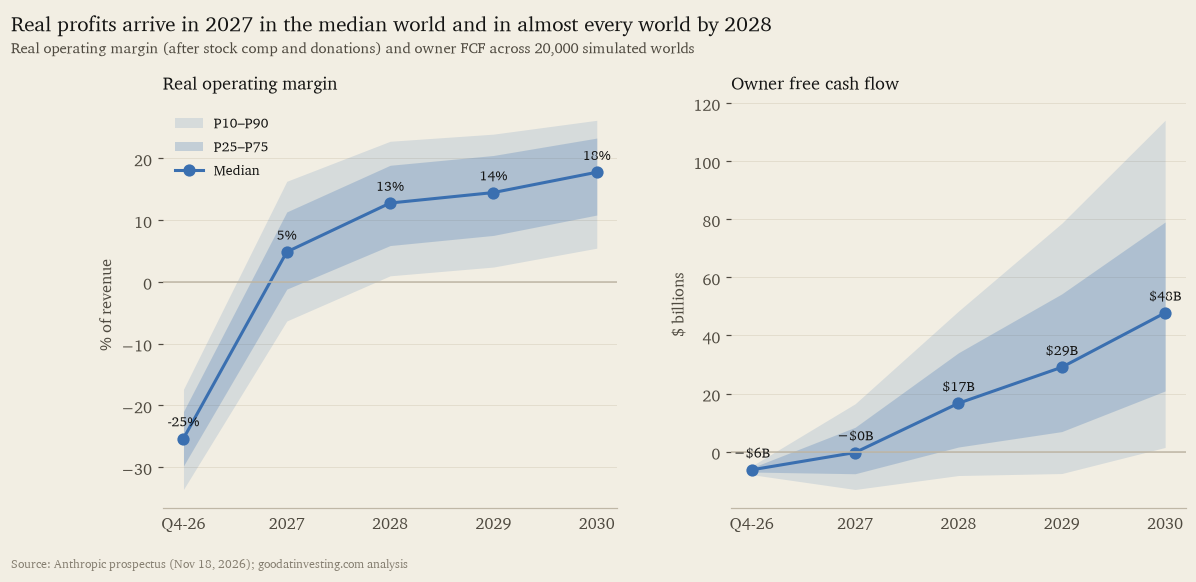

200 rows -> data/forecast.csv
20000 worlds -> data/forecast_worlds.csv


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
x = np.arange(len(YEARS))
fmt_pct = lambda v: f'{v:.0f}%'
fmt_usd = lambda v: ('−' if v < 0 else '') + f'${abs(v):,.0f}B'
for ax, m, scale, fmt, ylab, title in (
        (axes[0], 'real_operating_margin', 100, fmt_pct, '% of revenue', 'Real operating margin'),
        (axes[1], 'owner_fcf', 1 / B, fmt_usd, '$ billions', 'Owner free cash flow')):
    v = pct.loc[m] * scale
    ax.fill_between(x, v.loc['P10'], v.loc['P90'], color=SERIES[0], alpha=0.15, lw=0, label='P10–P90')
    ax.fill_between(x, v.loc['P25'], v.loc['P75'], color=SERIES[0], alpha=0.25, lw=0, label='P25–P75')
    ax.plot(x, v.loc['P50'], color=SERIES[0], marker='o', label='Median')
    for xi, yi in zip(x, v.loc['P50']):
        ax.annotate(fmt(yi), (xi, yi), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=9, color=INK)
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_xticks(x, ['Q4-26', '2027', '2028', '2029', '2030'])
    ax.tick_params(axis='x', length=0, labelcolor=INK2)
    ax.set_ylabel(ylab)
    ax.set_title(title, fontsize=11.5, pad=8)
axes[0].legend(loc='upper left', fontsize=9)
fig.suptitle('Real profits arrive in 2027 in the median world and in almost every world by 2028', x=0.01, ha='left', fontsize=14)
fig.text(0.01, 0.905, f'Real operating margin (after stock comp and donations) and owner FCF across {len(worlds):,} simulated worlds',
         color=INK2, fontsize=10)
fig.subplots_adjust(top=0.82, wspace=0.25)
source(fig)
save(fig, '06_margin_fcf.png')
plt.show()

out = pct.rename_axis(['metric', 'percentile']).reset_index().melt(id_vars=['metric', 'percentile'], var_name='period')
out.to_csv(DATA / 'forecast.csv', index=False)
print(len(out), 'rows -> data/forecast.csv')

# Per-world detail for 08 (valuation): each world's inputs, its Q4-2030 run-rate, and yearly revenue and owner FCF
worlds_out = worlds[['ceiling', 'speed', 'rev_per_compute']].assign(run_rate_q4_2030=path[-1])
for m in ('revenue', 'owner_fcf'):
    worlds_out = worlds_out.join(OUT[m].add_prefix(f'{m}_'))
worlds_out.round(4).to_csv(DATA / 'forecast_worlds.csv', index_label='world')
print(len(worlds_out), 'worlds -> data/forecast_worlds.csv')

**What this shows** (`06_margin_fcf.png`): the compute commitments put a floor under costs, so margins swing with revenue.
- **Q4-2026** is ugly in every world: the $8.2B stock-comp catch-up at IPO lands on top of a compute step-up.
- **2027:** 70% of worlds have positive real operating income. Committed compute roughly doubles, and revenue mostly outruns it.
- **2028–2030:** profitable in 93–100% of worlds. The breakeven ceiling printed above (~$224B a year) is at the bottom edge of the simulated range (2% of worlds sit below it), so treat it as rough. The margin that's left is set by efficiency: once a world outgrows its contracts, every extra dollar of revenue costs 1 ÷ (revenue per compute dollar) in compute.
- **Cash never runs out before 2030** in any world. Conventional FCF stays positive because stock comp and donations are non-cash. In the worst decile, the $132B pile still grows, to ~$246B by 2030. 03's bear case, which does run out, sits below all these worlds.

## Findings, by section
1. A Gompertz curve, where each quarter closes a fixed share of the log gap to a ceiling, is the standard shape for technology adoption: fast early slowdown, long tail. With the same ceiling, it's more conservative in 2027–28 than a logistic.
2. Fitting both the ceiling and the speed to six quarters fails (a ~$1.6 quintillion ceiling). Fixing the ceiling and fitting only the speed works: ~0.13–0.19 a quarter, so half the gap closes every 4–5 quarters.
3. The $895B is mostly rent and take-or-pay cloud contracts, not capex (real capex-like spend was ~$3B in 9M-2026). ~$437B sits in four must-pay deals; ~$214B can be terminated or depends on a partner's financing or permits; ~$150–175B more has no fixed price. About 14 years of today's revenue, ~$448B of it due before 2031.
4. The compute commitments imply a ceiling of ~$236B a year (~3.7x today's run-rate). That's the company's revealed forecast.
5. The simulation draws the ceiling from $40T × AI's share of wages (1.5–8%) × Anthropic's share of AI (30–55%), with the speed fitted to the data for each world. Median ceiling ~$570B, implied Q4 growth mostly 25–46% (P10–P90). The ~$236B the contracts imply is below ~97% of worlds.
6. Median revenue ~$155B (2027) and ~$524B (2030), P10–P90 $306–907B in 2030. 03's base case is ~P3, its bull case ~P77. 03's bear case is below every world.
7. Median real operating margin: +5% / +13% / +18% in 2027 / 2028 / 2030. Positive in 70% / 93% / ~100% of worlds. Breakeven ceiling ~$224B, at the bottom edge of the range. No world runs out of cash by 2030.

**Caveats**
- **The ceiling assumptions drive the forecast.** §2 shows the data can't find the ceiling, so the ranges for AI's share of wages and Anthropic's share of AI move almost everything. They're judgments, anchored to the S-1's TAM figures and to cloud's share of the $40T. The 30–55% share is on the optimistic side: it puts ~97% of worlds above what Anthropic's own compute contracts are sized for (§4; 09 §6 values the contracts' world on its own).
- Price cuts are inside the curve: a ceiling in dollars assumes usage grows faster than price falls (S-1: ~$600M of Q2→Q3 revenue lost to price reductions).
- The curves are smooth. The S-1 warns about seasonality and margins that swing as compute blocks come online, so real quarters will zig-zag around these paths.
- The speed is fitted to only six quarters, including a re-acceleration (H1-2026) and a drop driven by enforcement against policy violators (Q3). Its standard error is in the simulation, but the history is short.
- The partner split assumes every named fixed-price deal sits inside the $895.4B. The S-1 doesn't reconcile the two, so the "not itemized" bar is a residual, not a disclosed figure.
- The cost structure, compute schedule and cash mechanics are 03's, with the same caveats: payment timing beyond the S-1 table is our estimate, and taxes ignore NOLs.

**Open items:** re-run on the priced amendment. Run-Rate Revenue as of Oct 31 2026 adds a seventh data point for the speed fit and pins down Q4. Valuation: done in `08_valuation.ipynb` (from `forecast_worlds.csv`). S-1/A No. 2 (Nov 10) is on EDGAR but not yet extracted; the FWP gives ~$81B Run-Rate Revenue as of October 2026 (08 §6).